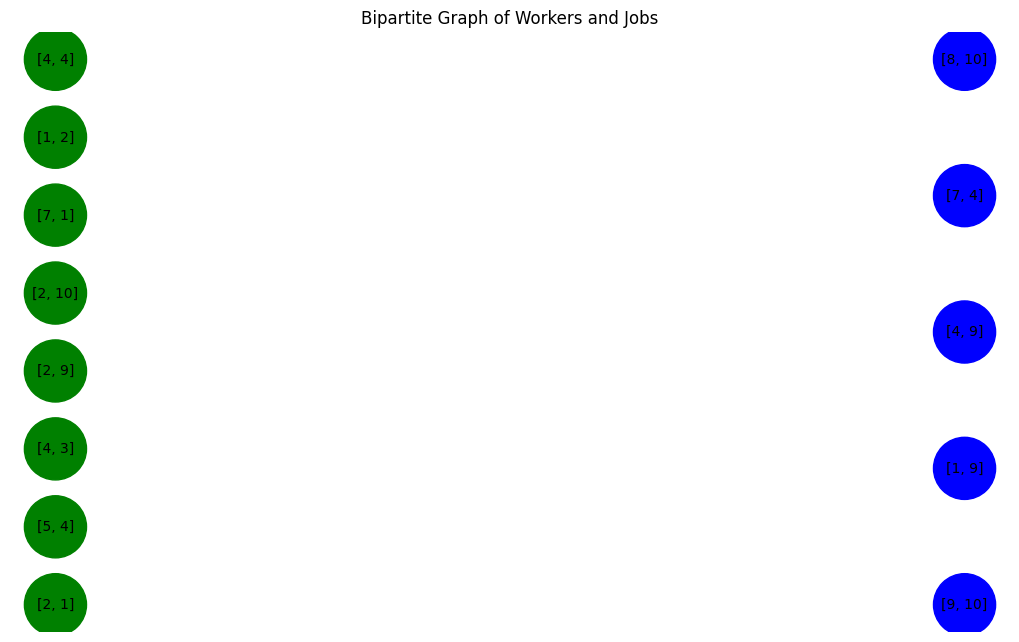

In [7]:
# Optimal Assignment visualization


import random

import networkx as nx


# Create a bipartite graph, with "workers" on one side and "jobs" on the other
# Each worker named W1, W2, W3 and each job named J1, J2, J3
# There are two tasks
# Each worker has a vector representing their skill level for each task.
# Each job has a vector representing required skill level for each task.
 
num_jobs = 5
num_workers = 8
num_tasks = 2

G = nx.Graph()
workers = [f'W{i+1}' for i in range(num_workers)]
jobs = [f'J{i+1}' for i in range(num_jobs)]

random.seed(42)  # For reproducibility

workers_skills = {worker: [random.randint(1, 10) for _ in range(num_tasks)] for worker in workers}
jobs_requirements = {job: [random.randint(1, 10) for _ in range(num_tasks)] for job in jobs}

G.add_nodes_from(workers, bipartite=0)
G.add_nodes_from(jobs, bipartite=1)

nx.set_node_attributes(G, workers_skills, 'skills')
nx.set_node_attributes(G, jobs_requirements, 'requirements')

# Plot the bipartite graph
# Workers are green, jobs are blue
# Skills are displayed as node labels for workers, and requirements for jobs

import matplotlib.pyplot as plt

def visualize_graph(G, workers, graph_title=None, edges=None):
    pos = nx.bipartite_layout(G, workers)
    node_colors = ['green' if node in workers else 'blue' for node in G.nodes()]
    node_labels = {node: G.nodes[node]['skills'] if node in workers else G.nodes[node]['requirements'] for node in G.nodes()}
    
    plt.figure(figsize=(10, 6))
    nx.draw(G, pos, with_labels=True, labels=node_labels, node_color=node_colors, node_size=2000, font_size=10)
    
    if edges:
        nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color='red', width=2)
    
    plt.title(graph_title if graph_title else "Bipartite Graph of Workers and Jobs")
    plt.axis('off')
    plt.show()
 
visualize_graph(G, workers, graph_title="Bipartite Graph of Workers and Jobs")


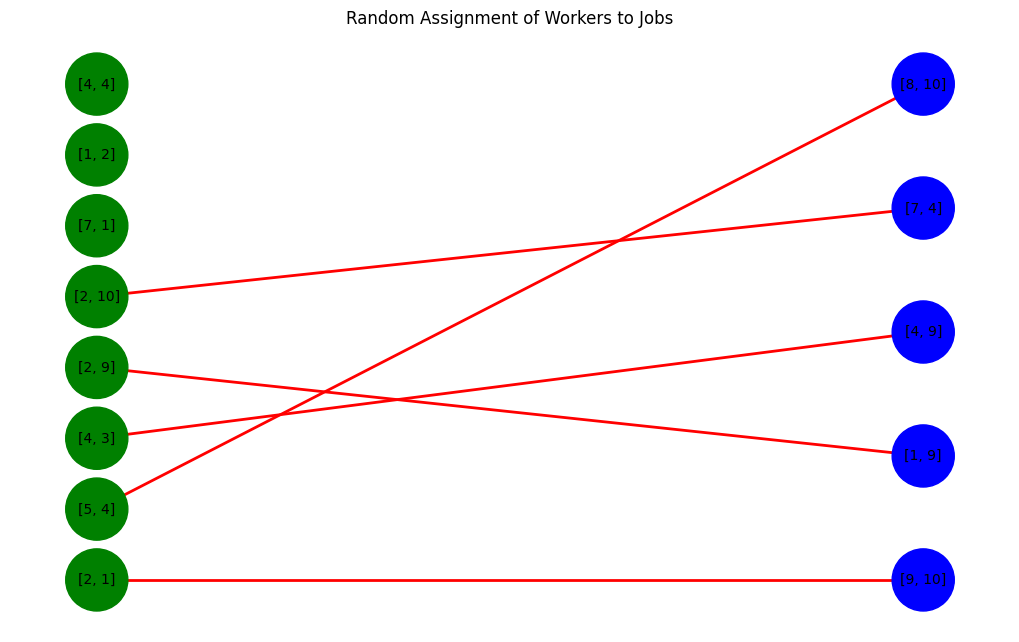

In [9]:
def random_assignment(workers, jobs):
    """Randomly assign workers to jobs."""
    assignments = {}
    available_jobs = jobs.copy()
    random.shuffle(available_jobs)
    
    for worker in workers:
        if available_jobs:
            job = available_jobs.pop()
            assignments[worker] = job
        else:
            assignments[worker] = None  # No job available
    
    return assignments

random.seed(42)
random_assignments = random_assignment(workers, jobs)
def visualize_assignments(G, assignments, workers, graph_title=None):
    edges = [(worker, job) for worker, job in assignments.items() if job is not None]
    visualize_graph(G, workers, graph_title=graph_title, edges=edges)

visualize_assignments(G, random_assignments, workers, graph_title="Random Assignment of Workers to Jobs")